# Catalogue Tour & Series Taxonomy

Before any analysis it pays to know **what exists, how far back it goes, and how to find it**. This notebook:

1. Maps the dataset landscape by asset class, family and history
2. Shows how to read a series label, with a decoder you can reuse
3. Searches the series dictionary for what you need
4. Profiles coverage by country, investor type and cadence
5. Explains the metric vocabulary

Everything here runs from the catalogues and the `Reference Data/` folder; no market data needs loading.

In [1]:
import re
import sys
from pathlib import Path

from dotenv import load_dotenv

sys.path.insert(0, str(Path.cwd().parent))
load_dotenv(Path.cwd().parent / ".env")

import pandas as pd
import matplotlib.pyplot as plt

import quantkit as qk

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)
qk.set_style()

ref = qk.series_reference()
datasets = qk.load_datasets()
print(f"{len(datasets)} datasets · {len(ref):,} series · {ref.n_dates.sum():,} series-days of history")

73 datasets · 1,238 series · 3,352,352 series-days of history


## 1. The dataset landscape

**Positioning** datasets are Vanda's combined scores: one z-score per market, sector, tenor or currency pair.
**Flow** datasets are the investor-level building blocks behind them, and many are useful signals in their own right.

In [2]:
by_class = (
    ref.groupby(["asset_type", "family"]).series_label.nunique().unstack(fill_value=0)
    .rename(index={"EQ": "Equity", "FI": "Fixed income", "FX": "FX", "COM": "Commodity", "CRYPTO": "Crypto"})
)
by_class["total"] = by_class.sum(axis=1)
by_class.sort_values("total", ascending=False)

family,flow,positioning,total
asset_type,,,
Equity,612,155,767
Commodity,157,23,180
Fixed income,148,29,177
FX,76,28,104
Crypto,10,0,10


### How far back does each dataset go?

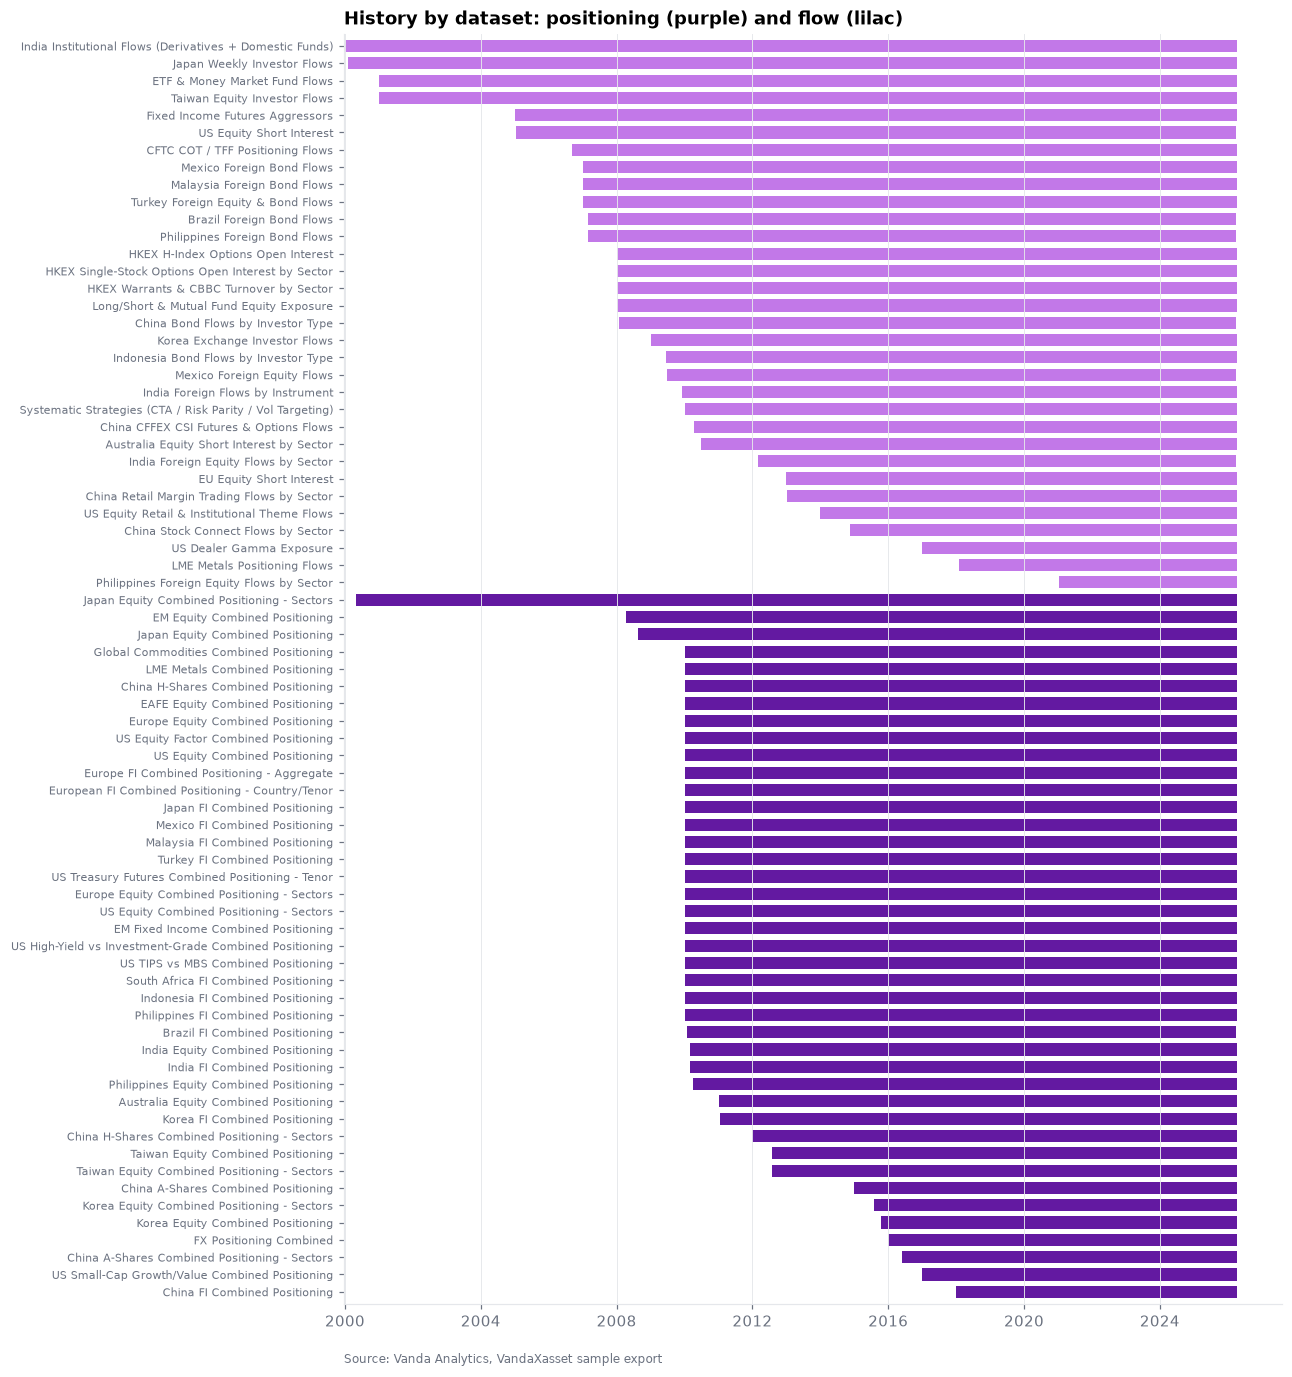

In [3]:
timeline = datasets.sort_values(["family", "first_ts"]).reset_index(drop=True)
colors = timeline.family.map({"positioning": qk.VANDA["purple"], "flow": qk.VANDA["lilac"]})

fig, ax = plt.subplots(figsize=(11, 15))
ax.barh(timeline.display_name, (timeline.last_ts - timeline.first_ts).dt.days, left=timeline.first_ts.dt.tz_localize(None), color=colors, height=0.7)
ax.invert_yaxis()
ax.margins(y=0.005)
ax.tick_params(axis="y", labelsize=7.5)
ax.set_title("History by dataset: positioning (purple) and flow (lilac)")
ax.grid(axis="y", visible=False)
qk.source_note(ax, "Source: Vanda Analytics, VandaXasset sample export")
plt.show()

## 2. Reading a series label

Every flow series code is built from fixed segments. Once you can read it, you can usually guess the code you need.

```
 KR   EQ   STCK   ·         FOR    MIX   MIX   MIX    -TECH
 │    │    │      │          │      │     │     │       └ optional slice (sector, tenor, pair)
 │    │    │      │          │      │     │     └ investor subtype   (CTA, RP, RET, DEA, LEV, ASS, ...)
 │    │    │      │          │      │     └ investor type          (SPE speculative, REA real money, COM commercial, ...)
 │    │    │      │          │      └ investor category            (INS institutional, IND individual)
 │    │    │      │          └ investor origin                     (DOM domestic, FOR foreign)
 │    │    │      └ benchmark / contract, may be empty             (ES1, TY1, CSI3, SPY, ...)
 │    │    └ instrument                                            (STCK, FUTU, OPTI, BOND, WARR, ...)
 │    └ asset class                                                (EQ, FI, FX, COM, CRYPTO)
 └ country / region                                                (ISO-2, GL global, EU, EM)
```

Positioning codes are shorter: market plus `COMB`, with an optional slice. For example `USEQCOMB`, `USEQCOMB-ENER`,
`USFICOMB-10YR` and `JPFXCOMB-USDJPY`.

The full code list ships as `Reference Data/VandaXasset-Label-Codes.csv`:

In [4]:
qk.label_codes().groupby("position").code.apply(lambda s: ", ".join(s)).to_frame("codes")

,codes
position,
asset_class,"EQ, FI, FX, COM, CRYPTO"
category,"INS, IND, MIX, COMB"
country,2 letters
instrument,"STCK, FUTU, OPTI, HOPT, BOND, WARR, ASHR, HSHR, CASH, PH..."
origin,"DOM, FOR, MIX"
subtype,"CTA, RP, VT, RET, ETF, MUT, PEN, DEA, LEV, ASS, MAN, SWA..."
suffix,"-COMS ... -UTIL, -2YR ... -30YR, -USDJPY etc., _BETA"
type,"SPE, REA, COM, PAS, BAN, MIX"


A small regular expression decodes **every** flow label in the catalogue. We check it against the dictionary below.

In [5]:
FLOW_LABEL = re.compile(
    r"^(?P<country>[A-Z]{2})"
    r"(?P<asset>EQ|FI|FX|COM|CRYPTO)"
    r"(?P<instrument>STCK|FUTU|OPTI|HOPT|BOND|WARR|ASHR|HSHR|CASH|PHYS|MIX)"
    r"(?P<benchmark>[A-Z0-9]*?)"
    r"(?P<origin>DOM|FOR|MIX)?"
    r"(?P<category>INSI|INS|IND|MIX)"
    r"(?P<type>SPE|REA|COM|PAS|BAN|MIX)"
    r"(?P<subtype>CTA|RP|VT|RET|ETF|MUT|PEN|DEA|LEV|ASS|MAN|SWA|PRO|AGG|LS|MIX)"
    r"(?P<slice>-[A-Z0-9-]+)?$"
)


def decode(label: str) -> dict:
    m = FLOW_LABEL.match(label)
    return {k: (v or "").lstrip("-") for k, v in m.groupdict().items()} if m else {}


for example in ["KREQSTCKFORMIXMIXMIX-TECH", "USEQFUTUES1MIXINSSPELEV", "GLCOMFUTUCL1MIXINSSPECTA", "USEQOPTISPYMIXINSCOMDEA"]:
    print(f"{example:28s}", decode(example), "→", qk.names([example])[example])

KREQSTCKFORMIXMIXMIX-TECH    {'country': 'KR', 'asset': 'EQ', 'instrument': 'STCK', 'benchmark': '', 'origin': 'FOR', 'category': 'MIX', 'type': 'MIX', 'subtype': 'MIX', 'slice': 'TECH'} → Korea Foreign inv. Tech
USEQFUTUES1MIXINSSPELEV      {'country': 'US', 'asset': 'EQ', 'instrument': 'FUTU', 'benchmark': 'ES1', 'origin': 'MIX', 'category': 'INS', 'type': 'SPE', 'subtype': 'LEV', 'slice': ''} → Leveraged Funds S&P500 E-mini
GLCOMFUTUCL1MIXINSSPECTA     {'country': 'GL', 'asset': 'COM', 'instrument': 'FUTU', 'benchmark': 'CL1', 'origin': 'MIX', 'category': 'INS', 'type': 'SPE', 'subtype': 'CTA', 'slice': ''} → CTA WTI Crude
USEQOPTISPYMIXINSCOMDEA      {'country': 'US', 'asset': 'EQ', 'instrument': 'OPTI', 'benchmark': 'SPY', 'origin': 'MIX', 'category': 'INS', 'type': 'COM', 'subtype': 'DEA', 'slice': ''} → Options Dealers S&P 500 E-mini


In [6]:
flow_ref = ref[ref.family == "flow"]
decoded = pd.DataFrame([decode(s) for s in flow_ref.series_label], index=flow_ref.index)

type_names = {"SPE": "Speculative", "REA": "Real money", "COM": "Commercial", "PAS": "Passive", "BAN": "Banks", "MIX": "Mixed"}
checks = pd.Series({
    "labels decoded": decoded["country"].ne("").mean(),
    "country matches dictionary": (decoded["country"] == flow_ref["country_code"]).mean(),
    "asset class matches": (decoded["asset"] == flow_ref["asset_type"]).mean(),
    "investor type matches": (decoded["type"].map(type_names) == flow_ref["investor_type"]).mean(),
})
checks.map("{:.1%}".format)

labels decoded                100.0%
country matches dictionary    100.0%
asset class matches           100.0%
investor type matches         100.0%
dtype: str

## 3. Search the series dictionary

`Reference Data/VandaXasset-Series-Reference.csv` has one row per series: name, description, dataset, taxonomy, metrics,
units, cadence, coverage and publication lag. Plain pandas filters answer most "do you have...?" questions.

**"Which foreign-investor equity flows do you have in Asia?"**

In [7]:
asia_foreign_equity = ref[
    (ref.family == "flow")
    & (ref.geography == "APAC")
    & (ref.asset_type == "EQ")
    & (ref.investor_origin == "Foreign")
    & ref.sector.isna()
]
asia_foreign_equity[["series_label", "name", "dataset", "frequency", "metrics", "first_ts"]]

,series_label,name,dataset,frequency,metrics,first_ts
67,CNEQASHRFORINSMIXMIX,China Foreign A-Shares,cn_stock_connect_flows,daily,net,2019-11-12
734,INEQSTCKFORINSMIXMIX,India Foreign Institutional Equities,in_foreign_flows_by_instrument,daily,buy;net;sell;total,2009-11-30
737,INEQFUTUFORINSSPEMIX,India Foreign Institutional Equity Futures,in_institutional_flows,daily,buy;net;sell;total,2009-11-30
739,INEQOPTIFORINSSPEMIX,India Foreign Institutional Equity Options,in_institutional_flows,daily,buy;net;sell;total,2009-11-30
746,JPEQFUTUFORINSMIXMIX,Japan Foreign Institutional Equity Futures,jp_investor_flows,daily,buy;net;sell;total,2015-01-09
750,JPEQOPTIFORINSMIXMIX,Japan Foreign Institutional Equity Options,jp_investor_flows,daily,buy;net;sell;total,2015-01-09
766,JPEQSTCKFORINSMIXMIX,Japan Foreign Institutional Equity,jp_investor_flows,daily,buy;net;sell;total,2005-01-07
782,KREQFUTUFORMIXMIXMIX,Korea Foreign inv. Equity Futures,kr_investor_flows,daily,buy_value;buy_volume;net_value;net_volume;sell_value;sel...,2009-01-02
788,KREQOPTIFORMIXMIXMIX,Korea Foreign inv. Equity Options,kr_investor_flows,daily,buy_value;buy_volume;net_value;net_volume;sell_value;sel...,2009-01-02
849,KREQSTCKFORMIXMIXMIX,Korea Foreign inv. Stocks,kr_investor_flows,daily,buy_value;buy_volume;net_value;net_volume;sell_value;sel...,2015-05-04


**"What does CFTC data cover for crude oil, and by which trader category?"**

In [8]:
crude = ref[(ref.dataset == "global_cftc_positioning_flows") & (ref.benchmark == "cl1 comdty")]
crude[["series_label", "name", "investor_type", "investor_subtype", "model_id", "first_ts"]]

,series_label,name,investor_type,investor_subtype,model_id,first_ts
231,GLCOMFUTUCL1MIXINSCOMMIX,Commercial inv. WTI Crude,Commercial,Mixed,CFTC,2006-09-05
232,GLCOMFUTUCL1MIXINSCOMPRO,Producers WTI Crude,Commercial,Producer,CFTC_DISAGG_COM,2006-09-05
233,GLCOMFUTUCL1MIXINSCOMSWA,Swap Dealers WTI Crude,Commercial,Swap dealer,CFTC_DISAGG_COM,2006-09-05
234,GLCOMFUTUCL1MIXINSSPEMAN,Managed Money WTI Crude,Speculative,Managed money,CFTC_DISAGG_COM,2006-09-05
235,GLCOMFUTUCL1MIXINSSPEMIX,Non-commercial inv. WTI Crude,Speculative,Mixed,CFTC,2006-09-05


**"Everything for Korea"**: positioning and the flows behind it.

In [9]:
korea = ref[ref.country_code == "KR"]
korea.groupby(["family", "dataset"]).agg(series=("series_label", "nunique"), since=("first_ts", "min"), metrics=("metrics", "first"))

series      since                                                      metrics
family      dataset                                                                                                     
flow        global_systematic_flows            3 2010-01-01  convex_10d;convex_1d;convex_5d;cum_net_10d;cum_net_1d;cu...
            kr_investor_flows                 90 2009-01-02  buy_value;buy_volume;net_value;net_volume;sell_value;sel...
positioning global_fx_positioning              1 2016-01-01                                         combined_positioning
            kr_equity_positioning              1 2015-10-19                                         combined_positioning
            kr_equity_sector_positioning      22 2015-07-31                                         combined_positioning
            kr_fixed_income_positioning        1 2011-01-19                                         combined_positioning

`qk.describe()` prints the full record for one series:

In [10]:
qk.describe("USFIFUTUTY1MIXINSSPELEV")

family                                                                      flow
series_label                                             USFIFUTUTY1MIXINSSPELEV
name                                                     Leveraged Funds US 10YR
description              Leveraged Funds investor positioning in US 10YR futures
dataset                                            global_cftc_positioning_flows
dataset_name                                    CFTC COT / TFF Positioning Flows
dataset_id                                                   FLOW.GL.CFTC.ALL.V1
dataset_version                                                                1
asset_type                                                                    FI
asset_subtype                                                            Futures
model_id                                                             CFTC_DISAGG
country                                                                       US
country_code                

## 4. Coverage profile

### Where is the coverage?

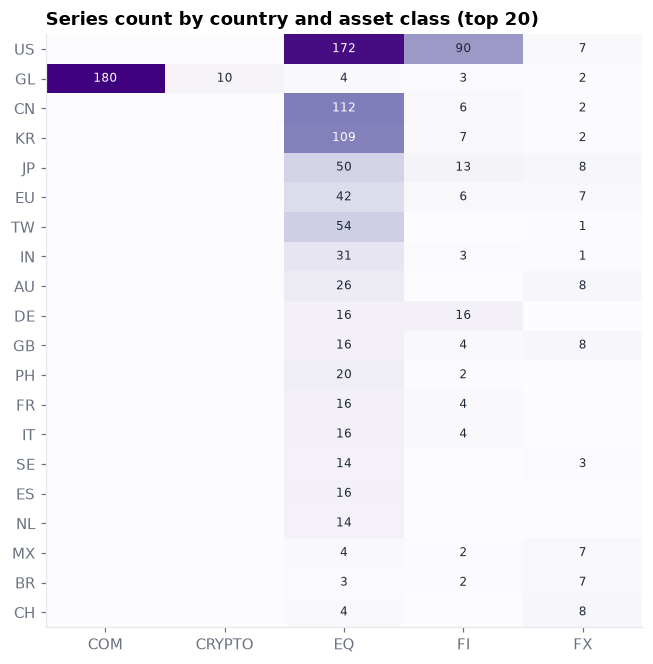

In [11]:
top_countries = ref.country_code.value_counts().head(20).index
grid = (
    ref[ref.country_code.isin(top_countries)]
    .pivot_table(index="country_code", columns="asset_type", values="series_label", aggfunc="nunique", fill_value=0)
    .loc[top_countries]
)

fig, ax = plt.subplots(figsize=(7, 7))
im = ax.imshow(grid.values, cmap="Purples", aspect="auto")
ax.set_xticks(range(grid.shape[1]), grid.columns)
ax.set_yticks(range(grid.shape[0]), grid.index)
for (i, j), v in pd.DataFrame(grid.values).stack().items():
    if v:
        ax.text(j, i, v, ha="center", va="center", fontsize=8, color="white" if v > grid.values.max() / 2 else qk.VANDA["ink"])
ax.grid(False)
ax.set_title("Series count by country and asset class (top 20)")
plt.show()

### Which investor types are measured?

In [12]:
investors = (
    ref[ref.family == "flow"]
    .groupby(["investor_type", "investor_subtype"]).series_label.nunique()
    .sort_values(ascending=False).rename("series").to_frame()
)
investors.head(20)

series
investor_type investor_subtype                      
Speculative   Mixed                              262
              CTA                                108
Mixed         Mixed                              107
Speculative   Risk Parity                         82
Passive       ETF                                 57
Commercial    Mixed                               55
              Dealer                              52
Speculative   Retail                              48
Mixed         Retail                              36
Speculative   Asset manager                       33
              Leveraged fund                      33
Commercial    Producer                            18
              Swap dealer                         18
Speculative   Managed money                       18
Banks         Mixed                               16
Real money    Pension funds                       16
              Mutual funds/Investment trusts      16
Speculative   Aggressors                          13
Real money    Mutual funds/Trusts                  5
Speculative   Long Short                           3

### Cadence and history length

Most positioning is daily from 2010. Flow cadence follows the source: exchanges publish daily, the CFTC weekly,
and some central banks monthly. Match your rebalance frequency to the slowest input you depend on.

In [13]:
cadence = ref.assign(years=(ref.last_ts - ref.first_ts).dt.days / 365.25)
cadence.groupby(["family", "frequency"]).agg(series=("series_label", "nunique"), median_years=("years", "median")).round(1)

series  median_years
family      frequency                      
flow        daily         726          14.1
            monthly        12          18.2
            weekly        265          19.6
positioning bi-weekly      11          13.8
            daily         198          14.3
            monthly         3          16.2
            weekly         23          16.3

## 5. Metric vocabulary

Flow metrics follow a small grammar. `net` is always buys minus sells; a suffix gives the window or unit.

| Metric | Meaning |
|---|---|
| `buy`, `sell`, `total`, `net` | Gross buying, gross selling, turnover (buy + sell) and net flow for the period |
| `buy_value` / `buy_volume` ... | Korea: the same in USD value or in contracts/shares |
| `*_raw` | In the source's native unit (contracts, or local currency) before conversion to USD |
| `exposure`, `exposure_net`, `exposure_long`, `exposure_short` | Outstanding position (a level, not a flow) |
| `exposure_as_perc_aum`, `net_as_perc_aum` | Systematic funds: exposure or flow as a share of modelled strategy AUM |
| `exposure_1d / _5d / _10d` | Systematic funds: the model's **projected** exposure 1, 5 or 10 market days ahead in its base case |
| `cum_net_1d / _5d / _10d` | The implied projected flow over that horizon, i.e. `exposure_Nd − exposure` |
| `new_long`, `new_short`, `closed_long`, `closed_short` | Futures aggressors: positions opened or closed (contracts, or `_usd`) |
| `exposure_gamma` | Dealer gamma exposure (USD mn), with 1, 5 and 10 day versions |
| `short_usd_perc`, `flow_usd_perc` | US short interest as a share of market cap, and its change |
| `combined_positioning` | **Positioning datasets:** the blended score, in σ from the series' own history |

Units are always explicit in the `unit` column. Most flows are converted to **USD mn**; the exceptions are a few
local-currency series, contract and share counts, and ratios. Always read `unit` before adding series together.

In [14]:
units = ref.assign(unit=ref.units.str.split(";")).explode("unit").groupby("unit").series_label.nunique().sort_values(ascending=False)
units.rename("series").to_frame()

,series
unit,
USDmn,987
contracts,294
count,272
zscore,235
pct_aum,192
days,191
shares,72
HKDmn,15
ratio,6


---
**Next:** `03 - Cross-Asset Crowding Screen`, which puts every positioning series on one scale.